In [4]:
#!pip install pyreadstat

In [5]:
#!pip install ollama

In [6]:
from pathlib import Path
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import pyreadstat
from ollama import chat

In [7]:
MODELO = "gemma2:9b"

RUTA_BASE = r"/content/Enaho01-2024-200.sav"


base, meta = pyreadstat.read_sav(RUTA_BASE)

# Copia de los metadatos de etiquetas de valores
etiquetas_valores = meta.variable_value_labels or {}
etiquetas_variables = meta.column_names_to_labels or {}


In [8]:
def normalizar(texto):
    texto = str(texto).lower().strip()
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )


def etiqueta_variable(variable):
    return etiquetas_variables.get(variable, variable)


def catalogo_variables():
    """Genera un catálogo compacto para orientar al LLM."""
    catalogo = []

    for variable in base.columns:
        valores = etiquetas_valores.get(variable, {})

        catalogo.append({
            "variable": variable,
            "etiqueta": etiqueta_variable(variable),
            "tipo_python": str(base[variable].dtype),
            "valores_distintos": int(
                base[variable].nunique(dropna=True)
            ),
            "ejemplos": [
                str(x) for x in base[variable]
                .dropna().drop_duplicates().head(3).tolist()
            ],
            "categorias": [
                str(k) + ": " + str(v)
                for k, v in list(valores.items())[:20]
            ],
        })

    return catalogo


CATALOGO = catalogo_variables()

In [9]:

# ============================================================
# 3. INTERPRETACION CON EL LLM
# ============================================================

def interpretar_consulta(pregunta):
    """
    Convierte la pregunta a un plan JSON.
    El LLM no ejecuta código.
    """

    prompt = f"""
Eres un asistente experto en análisis estadístico de encuestas.

Debes transformar la pregunta del usuario en un plan JSON.
Usa exclusivamente las variables del catálogo proporcionado.

Operaciones permitidas:
- frecuencia: distribución de una variable categórica.
- promedio: media de una variable numérica.
- conteo: número de filas que cumplen los filtros.

Reglas:
1. No inventes variables ni códigos.
2. Usa los nombres exactos del catálogo.
3. Para frecuencia, especifica variable.
4. Para promedio, especifica variable numérica.
5. Para conteo, variable puede ser null.
6. group_by puede ser null o una variable del catálogo.
7. Los filtros deben usar variables del catálogo y valores
   que existan en los datos o en sus etiquetas.
8. Si no puedes identificar la variable con suficiente
   confianza, devuelve operacion "no_identificada".
9. No calcules resultados ni inventes cifras.
10. Devuelve únicamente JSON válido.

Formato:
{{
  "operacion": "frecuencia",
  "variable": "NOMBRE_VARIABLE",
  "group_by": null,
  "filtros": [
    {{"variable": "OTRA_VARIABLE", "valor": "valor"}}
  ]
}}

CATÁLOGO:
{json.dumps(CATALOGO, ensure_ascii=False)}

PREGUNTA:
{pregunta}
"""

    respuesta = chat(
        model=MODELO,
        messages=[
            {
                "role": "system",
                "content": (
                    "Interpreta consultas estadísticas. "
                    "Devuelve exclusivamente un objeto JSON."
                ),
            },
            {"role": "user", "content": prompt},
        ],
        format="json",
        options={"temperature": 0},
    )

    return json.loads(respuesta.message.content)



In [10]:
# ============================================================
# 4. VALIDACION DEL PLAN
# ============================================================

OPERACIONES_PERMITIDAS = {
    "frecuencia",
    "promedio",
    "conteo",
}

def validar_plan(plan):
    if not isinstance(plan, dict):
        raise ValueError("El plan debe ser un objeto JSON.")

    operacion = plan.get("operacion")

    if operacion not in OPERACIONES_PERMITIDAS:
        raise ValueError(
            f"Operación no permitida: {operacion}"
        )

    variable = plan.get("variable")
    group_by = plan.get("group_by")
    filtros = plan.get("filtros", [])

    if variable is not None and variable not in base.columns:
        raise ValueError(f"Variable inexistente: {variable}")

    if operacion in {"frecuencia", "promedio"}:
        if variable is None:
            raise ValueError("Falta especificar la variable.")

    if operacion == "promedio":
        if not pd.api.types.is_numeric_dtype(base[variable]):
            raise ValueError(
                f"{variable} no es numérica. "
                "No se calculará un promedio."
            )

    if group_by is not None and group_by not in base.columns:
        raise ValueError(f"Grupo inexistente: {group_by}")

    if not isinstance(filtros, list):
        raise ValueError("Los filtros deben ser una lista.")

    for filtro in filtros:
        if not isinstance(filtro, dict):
            raise ValueError("Formato de filtro inválido.")

        var = filtro.get("variable")

        if var not in base.columns:
            raise ValueError(f"Variable de filtro inválida: {var}")

        if "valor" not in filtro:
            raise ValueError("Falta el valor de un filtro.")

    return True

In [11]:

# ============================================================
# 5. RESOLUCION DE CATEGORIAS Y FILTROS
# ============================================================

def resolver_valor(variable, valor):
    """
    Acepta tanto el código almacenado como su etiqueta SPSS.
    Devuelve un valor compatible con la columna original.
    """
    serie = base[variable]
    etiquetas = etiquetas_valores.get(variable, {})

    texto = normalizar(valor)

    # Coincidencia con las etiquetas de valores
    for codigo, etiqueta in etiquetas.items():
        if normalizar(etiqueta) == texto:
            return codigo

    # Coincidencia con valores observados
    for observado in serie.dropna().unique():
        if normalizar(observado) == texto:
            return observado

        if normalizar(str(observado)) == texto:
            return observado

    raise ValueError(
        f"No se encontró el valor '{valor}' en {variable}."
    )


def aplicar_filtros(df, filtros):
    resultado = df.copy()

    for filtro in filtros:
        variable = filtro["variable"]
        valor = resolver_valor(variable, filtro["valor"])

        resultado = resultado[
            resultado[variable] == valor
        ]

    return resultado


def mostrar_etiqueta(variable, valor):
    etiquetas = etiquetas_valores.get(variable, {})

    for codigo, etiqueta in etiquetas.items():
        if codigo == valor:
            return str(etiqueta)

    return str(valor)


In [12]:

# ============================================================
# 6. MOTOR ESTADISTICO
# ============================================================

def ejecutar_consulta(plan):
    validar_plan(plan)

    df = aplicar_filtros(base, plan.get("filtros", []))

    operacion = plan["operacion"]
    variable = plan.get("variable")
    group_by = plan.get("group_by")

    if df.empty:
        return {
            "mensaje": "No hay registros para los filtros indicados."
        }

    if operacion == "conteo":
        if group_by:
            resultado = (
                df.groupby(group_by, dropna=False)
                .size()
                .rename("frecuencia")
                .reset_index()
            )

            resultado[group_by] = resultado[group_by].map(
                lambda x: mostrar_etiqueta(group_by, x)
                if pd.notna(x) else "Sin dato"
            )

            return resultado

        return {"registros": int(len(df))}

    if operacion == "frecuencia":
        if group_by and group_by != variable:
            resultado = (
                df.groupby(
                    [group_by, variable],
                    dropna=False,
                )
                .size()
                .rename("frecuencia")
                .reset_index()
            )

            resultado["porcentaje"] = (
                resultado["frecuencia"]
                / resultado.groupby(group_by)["frecuencia"]
                    .transform("sum")
                * 100
            ).round(2)

            resultado[group_by] = resultado[group_by].map(
                lambda x: mostrar_etiqueta(group_by, x)
                if pd.notna(x) else "Sin dato"
            )

            resultado[variable] = resultado[variable].map(
                lambda x: mostrar_etiqueta(variable, x)
                if pd.notna(x) else "Sin dato"
            )

        else:
            resultado = (
                df[variable]
                .value_counts(dropna=False)
                .rename_axis(variable)
                .reset_index(name="frecuencia")
            )

            resultado["porcentaje"] = (
                resultado["frecuencia"] / len(df) * 100
            ).round(2)

            resultado[variable] = resultado[variable].map(
                lambda x: mostrar_etiqueta(variable, x)
                if pd.notna(x) else "Sin dato"
            )

        return resultado

    if operacion == "promedio":
        if group_by:
            resultado = (
                df.groupby(group_by, dropna=False)[variable]
                .agg(["mean", "count"])
                .reset_index()
            )

            resultado = resultado.rename(columns={
                "mean": "promedio",
                "count": "n_observaciones",
            })

            resultado["promedio"] = resultado["promedio"].round(3)

            resultado[group_by] = resultado[group_by].map(
                lambda x: mostrar_etiqueta(group_by, x)
                if pd.notna(x) else "Sin dato"
            )

            return resultado

        return {
            "variable": variable,
            "promedio": round(float(df[variable].mean()), 3),
            "n_observaciones": int(df[variable].count()),
        }


# ============================================================
# 7. RESPUESTA EN LENGUAJE NATURAL
# ============================================================

def explicar_resultado(pregunta, plan, resultado):
    if isinstance(resultado, pd.DataFrame):
        datos = resultado.head(50).to_dict(orient="records")
    else:
        datos = resultado

    prompt = f"""
Responde en español la pregunta estadística del usuario.

Pregunta: {pregunta}

Plan ejecutado:
{json.dumps(plan, ensure_ascii=False)}

Resultado calculado por Python:
{json.dumps(datos, ensure_ascii=False, default=str)}

Reglas:
- Usa exclusivamente las cifras del resultado.
- No inventes conclusiones ni causalidad.
- Indica que los porcentajes son frecuencias no ponderadas
  si no se ha aplicado un ponderador.
- Si el resultado es una tabla, resume los hallazgos principales.
- Si faltan datos para responder, indícalo.
"""

    respuesta = chat(
        model=MODELO,
        messages=[{"role": "user", "content": prompt}],
        options={"temperature": 0},
    )

    return respuesta.message.content



In [13]:

# ============================================================
# 8. INTERFAZ DE CONSOLA
# ============================================================

def consultar(pregunta):
    plan = interpretar_consulta(pregunta)
    print("\nPlan propuesto:", json.dumps(
        plan, ensure_ascii=False, indent=2
    ))

    validar_plan(plan)
    resultado = ejecutar_consulta(plan)

    print("\nResultado calculado:")

    if isinstance(resultado, pd.DataFrame):
        print(resultado.to_string(index=False))
    else:
        print(resultado)

    explicacion = explicar_resultado(
        pregunta, plan, resultado
    )

    print("\nRespuesta del chatbot:")
    print(explicacion)

    return plan, resultado, explicacion


# Experimentos de hiperparámetros

El baseline usa un único ajuste (`temperature=0`, resto por defecto de Ollama). Aquí se mide **cuánto cambia la
calidad del plan JSON** al variar cada hiperparámetro.

**Método**
1. Un conjunto de preguntas con su plan correcto (*gold*).
2. Para cada configuración se calculan: `exec_ok` (el plan propuesto produce **el mismo resultado** que el gold, métrica principal), `exact` (variable, group_by y filtros idénticos), `plan_valido`, latencia, tokens del prompt y si el prompt se truncó.
3. Se explora **un factor a la vez** (búsqueda greedy): cada experimento parte de la mejor configuración del anterior, y siempre incluye esa configuración como referencia para no retroceder.

Orden: `num_ctx` → catálogo → prompt/formato → temperatura → penalización/muestreo → modelo.

In [14]:
# ============================================================
# 9. EXPERIMENTOS: CONFIGURACION, PROMPT Y LLAMADA AL LLM
# ============================================================
import time
from dataclasses import dataclass, replace, asdict
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print


@dataclass(frozen=True)
class Config:
    """None = no se envía el parámetro (Ollama usa su valor por defecto).
    Config() reproduce exactamente el baseline."""
    nombre: str = "baseline"
    modelo: str = MODELO
    temperature: float = 0.0
    top_p: float = None
    top_k: int = None
    repeat_penalty: float = None
    num_ctx: int = None
    num_predict: int = None
    seed: int = 42
    max_categorias: int = 20      # categorías por variable en el catálogo
    n_ejemplos: int = 3           # valores de ejemplo por variable
    prompt: str = "base"          # "base" | "fewshot"
    formato: str = "json"         # "json" | "schema" (salida estructurada)


_CACHE_CAT = {}


def catalogo_cfg(max_categorias=20, n_ejemplos=3):
    """Catálogo parametrizable (con 20 y 3 es idéntico al baseline)."""
    clave = (max_categorias, n_ejemplos)

    if clave not in _CACHE_CAT:
        catalogo = []

        for variable in base.columns:
            valores = etiquetas_valores.get(variable, {})

            item = {
                "variable": variable,
                "etiqueta": etiqueta_variable(variable),
                "tipo_python": str(base[variable].dtype),
                "valores_distintos": int(
                    base[variable].nunique(dropna=True)
                ),
            }

            if n_ejemplos > 0:
                item["ejemplos"] = [
                    str(x) for x in base[variable]
                    .dropna().drop_duplicates().head(n_ejemplos).tolist()
                ]

            if max_categorias > 0:
                item["categorias"] = [
                    str(k) + ": " + str(v)
                    for k, v in list(valores.items())[:max_categorias]
                ]

            catalogo.append(item)

        _CACHE_CAT[clave] = catalogo

    return _CACHE_CAT[clave]


def buscar_variable(*claves):
    """Busca una variable por palabras de su etiqueta (evita fijar códigos a mano)."""
    for var, etiqueta in etiquetas_variables.items():
        t = normalizar(etiqueta)
        if all(normalizar(c) in t for c in claves):
            return var
    return None


VAR_SEXO = buscar_variable("sexo")
VAR_EDAD = buscar_variable("edad")
VAR_ECIVIL = buscar_variable("estado civil")
VAR_PARENT = buscar_variable("parentesco")
VAR_LEER = buscar_variable("leer")

print("Variables detectadas:", dict(
    sexo=VAR_SEXO, edad=VAR_EDAD, estado_civil=VAR_ECIVIL,
    parentesco=VAR_PARENT, leer_escribir=VAR_LEER,
))


def ejemplos_fewshot():
    """Ejemplos distintos a las preguntas de evaluación (evita fuga)."""
    return f"""
EJEMPLOS:
Pregunta: Porcentaje de hombres según relación de parentesco
{{"operacion": "frecuencia", "variable": "{VAR_PARENT}", "group_by": null, "filtros": [{{"variable": "{VAR_SEXO}", "valor": "Hombre"}}]}}

Pregunta: Edad promedio según relación de parentesco
{{"operacion": "promedio", "variable": "{VAR_EDAD}", "group_by": "{VAR_PARENT}", "filtros": []}}

Pregunta: ¿Cuántas personas hay por estado civil?
{{"operacion": "conteo", "variable": null, "group_by": "{VAR_ECIVIL}", "filtros": []}}

Pregunta: ¿Cuál es el gasto mensual en alimentos?
{{"operacion": "no_identificada", "variable": null, "group_by": null, "filtros": []}}
"""


def construir_prompt(pregunta, cfg):
    catalogo = catalogo_cfg(cfg.max_categorias, cfg.n_ejemplos)
    ejemplos = ejemplos_fewshot() if cfg.prompt == "fewshot" else ""

    return f"""
Eres un asistente experto en análisis estadístico de encuestas.

Debes transformar la pregunta del usuario en un plan JSON.
Usa exclusivamente las variables del catálogo proporcionado.

Operaciones permitidas:
- frecuencia: distribución de una variable categórica.
- promedio: media de una variable numérica.
- conteo: número de filas que cumplen los filtros.

Reglas:
1. No inventes variables ni códigos.
2. Usa los nombres exactos del catálogo.
3. Para frecuencia, especifica variable.
4. Para promedio, especifica variable numérica.
5. Para conteo, variable puede ser null.
6. group_by puede ser null o una variable del catálogo.
7. Los filtros deben usar variables del catálogo y valores
   que existan en los datos o en sus etiquetas.
8. Si no puedes identificar la variable con suficiente
   confianza, devuelve operacion "no_identificada".
9. No calcules resultados ni inventes cifras.
10. Devuelve únicamente JSON válido.

Formato:
{{
  "operacion": "frecuencia",
  "variable": "NOMBRE_VARIABLE",
  "group_by": null,
  "filtros": [
    {{"variable": "OTRA_VARIABLE", "valor": "valor"}}
  ]
}}
{ejemplos}
CATÁLOGO:
{json.dumps(catalogo, ensure_ascii=False)}

PREGUNTA:
{pregunta}
"""


def esquema_plan():
    """JSON Schema: obliga al LLM a usar solo variables que existen."""
    cols = list(base.columns)
    var_o_null = {"anyOf": [
        {"type": "string", "enum": cols},
        {"type": "null"},
    ]}

    return {
        "type": "object",
        "properties": {
            "operacion": {
                "type": "string",
                "enum": ["frecuencia", "promedio", "conteo", "no_identificada"],
            },
            "variable": var_o_null,
            "group_by": var_o_null,
            "filtros": {
                "type": "array",
                "items": {
                    "type": "object",
                    "properties": {
                        "variable": {"type": "string", "enum": cols},
                        "valor": {"type": "string"},
                    },
                    "required": ["variable", "valor"],
                },
            },
        },
        "required": ["operacion", "variable", "group_by", "filtros"],
    }


def llamar_llm(pregunta, cfg):
    """Devuelve (plan, info). Lanza excepción si el LLM o el JSON fallan."""
    opciones = {"temperature": cfg.temperature}

    for k in ("top_p", "top_k", "repeat_penalty",
              "num_ctx", "num_predict", "seed"):
        valor = getattr(cfg, k)
        if valor is not None:
            opciones[k] = valor

    t0 = time.perf_counter()

    respuesta = chat(
        model=cfg.modelo,
        messages=[
            {
                "role": "system",
                "content": (
                    "Interpreta consultas estadísticas. "
                    "Devuelve exclusivamente un objeto JSON."
                ),
            },
            {"role": "user", "content": construir_prompt(pregunta, cfg)},
        ],
        format="json" if cfg.formato == "json" else esquema_plan(),
        options=opciones,
    )

    info = {
        "latencia_s": time.perf_counter() - t0,
        "tokens_prompt": getattr(respuesta, "prompt_eval_count", None),
        "tokens_salida": getattr(respuesta, "eval_count", None),
    }

    return json.loads(respuesta.message.content), info

Variables detectadas: {'sexo': 'P207', 'edad': 'P208A', 'estado_civil': 'P209', 'parentesco': 'P203', 'leer_escribir': None}


In [20]:
# ============================================================
# 10. CONJUNTO DE EVALUACION (GOLD)
# ============================================================
# Los planes correctos se construyen con las variables detectadas arriba.
# Revisa la salida de la validación: si algún gold falla, corrige el valor
# o la variable. Conviene ampliar a 30+ preguntas para resultados estables.

def F(variable, valor):
    return {"variable": variable, "valor": valor}


def plan(op, variable=None, group_by=None, filtros=None):
    return {"operacion": op, "variable": variable,
            "group_by": group_by, "filtros": filtros or []}


GOLD = [
    {"id": "G01", "pregunta": "¿Cuántas personas hay en la encuesta?",
     "plan": plan("conteo")},
    {"id": "G02", "pregunta": "¿Cuál es la distribución por sexo?",
     "plan": plan("frecuencia", VAR_SEXO)},
    {"id": "G03", "pregunta": "¿Cuál es la edad promedio de las personas?",
     "plan": plan("promedio", VAR_EDAD)},
    {"id": "G04", "pregunta": "¿Cuál es la edad promedio según sexo?",
     "plan": plan("promedio", VAR_EDAD, VAR_SEXO)},
    {"id": "G05", "pregunta": "¿Cuántas mujeres hay?",
     "plan": plan("conteo", filtros=[F(VAR_SEXO, "Mujer")])},
    {"id": "G06", "pregunta": "¿Cómo se distribuye el estado civil entre las mujeres?",
     "plan": plan("frecuencia", VAR_ECIVIL, filtros=[F(VAR_SEXO, "Mujer")])},
    {"id": "G07", "pregunta": "Distribución del estado civil por sexo",
     "plan": plan("frecuencia", VAR_ECIVIL, VAR_SEXO)},
    {"id": "G08", "pregunta": "Dime la edad media de los hombres",
     "plan": plan("promedio", VAR_EDAD, filtros=[F(VAR_SEXO, "Hombre")])},
    {"id": "G09", "pregunta": "¿Cuántos hombres hay por estado civil?",
     "plan": plan("conteo", group_by=VAR_ECIVIL, filtros=[F(VAR_SEXO, "Hombre")])},
    {"id": "G10", "pregunta": "¿Cómo se distribuye la relación de parentesco con el jefe del hogar?",
     "plan": plan("frecuencia", VAR_PARENT)},
    {"id": "G11", "pregunta": "¿Cuál es el ingreso promedio de los hogares?",
     "plan": plan("no_identificada")},
    {"id": "G12", "pregunta": "Edad promedio de las mujeres por estado civil",
     "plan": plan("promedio", VAR_EDAD, VAR_ECIVIL, [F(VAR_SEXO, "Mujer")])},
    {"id": "G13", "pregunta": "Porcentaje de personas según sexo y estado civil",
     "plan": plan("frecuencia", VAR_ECIVIL, VAR_SEXO)},
]


def preparar_gold():
    """Ejecuta cada plan gold y guarda su resultado para comparar."""
    validos = []

    for g in GOLD:
        p = g["plan"]

        if p["operacion"] == "no_identificada":
            g["resultado"] = None
            validos.append(g)
            continue

        try:
            g["resultado"] = ejecutar_consulta(p)
            validos.append(g)
        except Exception as e:
            print(f"[GOLD INVALIDO] {g['id']} {g['pregunta']} -> {e}")

    print(f"Gold válido: {len(validos)}/{len(GOLD)} preguntas")
    return validos


GOLD_OK = preparar_gold()


# ---------- metricas ----------

def _norm_filtros(filtros):
    salida = set()
    for f in filtros or []:
        var = f.get("variable")
        try:
            val = resolver_valor(var, f.get("valor"))
        except Exception:
            val = normalizar(f.get("valor"))
        salida.add((var, str(val)))
    return salida


def _resultados_iguales(a, b):
    """Siempre devuelve un bool (nunca un DataFrame)."""
    try:
        a_df, b_df = isinstance(a, pd.DataFrame), isinstance(b, pd.DataFrame)

        if a_df != b_df:          # tabla vs. dict: no son comparables
            return False

        if a_df:
            if set(a.columns) != set(b.columns):
                return False
            cols = sorted(a.columns)
            a2 = a[cols].astype(str).sort_values(cols).reset_index(drop=True)
            b2 = b[cols].astype(str).sort_values(cols).reset_index(drop=True)
            return bool(a2.equals(b2))

        return bool(a == b)
    except Exception:
        return False


def puntuar(plan_pred, gold):
    gp = gold["plan"]
    m = dict(json_ok=isinstance(plan_pred, dict), plan_valido=False,
             op_ok=False, var_ok=False, group_ok=False,
             filtros_ok=False, exec_ok=False)

    if not m["json_ok"]:
        return m

    m["op_ok"] = plan_pred.get("operacion") == gp["operacion"]
    m["var_ok"] = plan_pred.get("variable") == gp["variable"]
    m["group_ok"] = plan_pred.get("group_by") == gp["group_by"]
    m["filtros_ok"] = (
        _norm_filtros(plan_pred.get("filtros"))
        == _norm_filtros(gp["filtros"])
    )

    if gp["operacion"] == "no_identificada":
        m["plan_valido"] = m["exec_ok"] = m["op_ok"]
        return m

    try:
        validar_plan(plan_pred)
        m["plan_valido"] = True
        m["exec_ok"] = _resultados_iguales(
            ejecutar_consulta(plan_pred), gold["resultado"]
        )
    except Exception:
        pass

    return m

Gold válido: 13/13 preguntas


In [21]:
# ============================================================
# 11. MOTOR DE EXPERIMENTOS
# ============================================================
RESULTADOS = []


def correr_config(cfg, experimento, repeticiones=1):
    # Con temperature=0 las repeticiones serían idénticas.
    n_rep = 1 if cfg.temperature == 0 else repeticiones

    for rep in range(n_rep):
        cfg_i = replace(cfg, seed=(cfg.seed or 0) + rep)

        for g in GOLD_OK:
            try:
                plan_pred, info = llamar_llm(g["pregunta"], cfg_i)
                error = None
            except Exception as e:
                plan_pred, info = None, {}
                error = f"{type(e).__name__}: {str(e)[:150]}"

            m = puntuar(plan_pred, g)
            tp = info.get("tokens_prompt")

            fila = {
                "experimento": experimento,
                "config": cfg.nombre,
                **{k: v for k, v in asdict(cfg).items() if k != "nombre"},
                "rep": rep,
                "id": g["id"],
                "pregunta": g["pregunta"],
                **m,
                "exact": (m["op_ok"] and m["var_ok"]
                          and m["group_ok"] and m["filtros_ok"]),
                "latencia_s": info.get("latencia_s"),
                "tokens_prompt": tp,
                "posible_truncado": bool(
                    cfg.num_ctx is not None and tp is not None
                    and tp >= cfg.num_ctx - 8
                ),
                "plan_pred": json.dumps(plan_pred, ensure_ascii=False),
                "error": error,
            }
            RESULTADOS.append(fila)

            # Modelo no descargado: no tiene sentido seguir
            if error and "not found" in error.lower():
                print(f"   ! {cfg.modelo} no está disponible "
                      f"(ejecuta: !ollama pull {cfg.modelo})")
                return


def resumir(df):
    por_rep = (
        df.groupby(["config", "rep"], sort=False)
        .agg(exec_ok=("exec_ok", "mean"))
        .reset_index()
    )

    acc = por_rep.groupby("config", sort=False).agg(
        exec_acc=("exec_ok", "mean"),
        exec_std=("exec_ok", "std"),
    )

    resto = df.groupby("config", sort=False).agg(
        exact=("exact", "mean"),
        plan_valido=("plan_valido", "mean"),
        op_ok=("op_ok", "mean"),
        var_ok=("var_ok", "mean"),
        filtros_ok=("filtros_ok", "mean"),
        latencia_s=("latencia_s", "mean"),
        tokens_prompt=("tokens_prompt", "mean"),
        truncado=("posible_truncado", "mean"),
        errores=("error", lambda s: int(s.notna().sum())),
    )

    out = acc.join(resto)
    out["exec_std"] = out["exec_std"].fillna(0)
    return out.round(3)


def elegir_mejor(res, cfgs):
    """Mayor exec_acc; desempata por menor varianza y menor latencia."""
    orden = res.sort_values(
        ["exec_acc", "exec_std", "latencia_s"],
        ascending=[False, True, True],
    )
    return next(c for c in cfgs if c.nombre == orden.index[0])


def correr_experimento(nombre, cfgs, repeticiones=1):
    inicio = len(RESULTADOS)

    for cfg in cfgs:
        print(f"→ {nombre}: {cfg.nombre}", flush=True)
        correr_config(cfg, nombre, repeticiones)

    res = resumir(pd.DataFrame(RESULTADOS[inicio:]))
    mejor = elegir_mejor(res, cfgs)
    display(res)
    print(f"Mejor configuración del experimento: {mejor.nombre}")
    return res, mejor


def grafico(res, titulo):
    ax = res["exec_acc"].plot.barh(
        xerr=res["exec_std"], figsize=(7, 0.45 * len(res) + 1.5),
        xlim=(0, 1.05), title=titulo,
    )
    ax.set_xlabel("exec_acc (resultado igual al gold)")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


BASE = Config()       # = baseline original
MEJOR = BASE          # se actualiza tras cada experimento
N_REP = 3             # repeticiones cuando temperature > 0

## E0 · Baseline
Reproduce el comportamiento original (sin `num_ctx` explícito, sin few-shot, `format="json"`).

In [22]:
res0, _ = correr_experimento("E0_baseline", [BASE])

→ E0_baseline: baseline


,exec_acc,exec_std,exact,plan_valido,op_ok,var_ok,filtros_ok,latencia_s,tokens_prompt,truncado,errores
config,,,,,,,,,,,
baseline,0.0,0.0,0.0,0.0,0.0,0.0,0.615,8.639,2051.0,0.0,1


Mejor configuración del experimento: baseline


## E1 · Ventana de contexto (`num_ctx`)
El catálogo completo se inserta en el prompt. Si supera el contexto de Ollama el prompt **se trunca en silencio**
y el modelo deja de ver variables. La columna `truncado` lo detecta (`tokens_prompt` ≈ `num_ctx`).
Nota: `gemma2` admite como máximo 8192 tokens.

Catálogo base: 14,313 caracteres ≈ 4,771 tokens (estimación)
→ E1_num_ctx: ctx=default
→ E1_num_ctx: ctx=2048
→ E1_num_ctx: ctx=4096
→ E1_num_ctx: ctx=8192


,exec_acc,exec_std,exact,plan_valido,op_ok,var_ok,filtros_ok,latencia_s,tokens_prompt,truncado,errores
config,,,,,,,,,,,
ctx=default,0.000,0.0,0.000,0.000,0.000,0.000,0.615,5.799,2051.000,0.0,1
ctx=2048,0.000,0.0,0.000,0.000,0.000,0.000,0.615,7.745,1027.000,0.0,1
ctx=4096,0.000,0.0,0.000,0.000,0.000,0.000,0.615,7.958,2051.000,0.0,1
ctx=8192,0.538,0.0,0.462,0.769,0.769,0.615,0.923,6.200,5407.083,0.0,1


Mejor configuración del experimento: ctx=8192


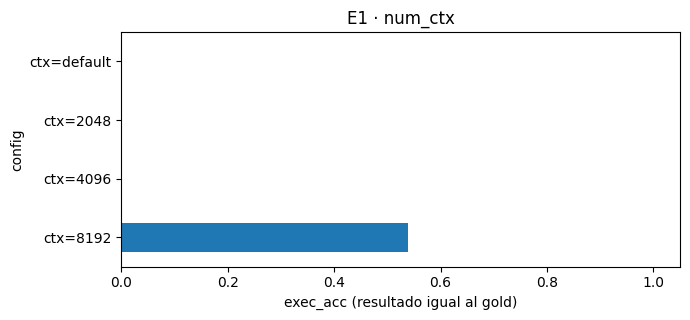

In [23]:
chars = len(json.dumps(catalogo_cfg(20, 3), ensure_ascii=False))
print(f"Catálogo base: {chars:,} caracteres ≈ {chars // 3:,} tokens (estimación)")

cfgs = [
    replace(MEJOR, nombre=f"ctx={c or 'default'}", num_ctx=c)
    for c in (None, 2048, 4096, 8192)
]

res1, MEJOR = correr_experimento("E1_num_ctx", cfgs)
grafico(res1, "E1 · num_ctx")

## E2 · Tamaño del catálogo
Más categorías y ejemplos dan más información, pero consumen contexto y pueden confundir al modelo.

→ E2_catalogo: cat=0/ej=0
→ E2_catalogo: cat=0/ej=3
→ E2_catalogo: cat=5/ej=0
→ E2_catalogo: cat=5/ej=3
→ E2_catalogo: cat=20/ej=0
→ E2_catalogo: cat=20/ej=3
→ E2_catalogo: cat=50/ej=0
→ E2_catalogo: cat=50/ej=3


,exec_acc,exec_std,exact,plan_valido,op_ok,var_ok,filtros_ok,latencia_s,tokens_prompt,truncado,errores
config,,,,,,,,,,,
cat=0/ej=0,0.538,0.0,0.538,1.000,0.923,0.846,0.615,3.669,2090.077,0.0,0
cat=0/ej=3,0.615,0.0,0.615,1.000,0.923,0.846,0.769,3.905,2962.077,0.0,0
cat=5/ej=0,0.615,0.0,0.615,0.923,0.846,0.769,1.000,4.199,3209.077,0.0,0
cat=5/ej=3,0.615,0.0,0.615,0.923,0.846,0.769,0.923,7.486,4041.000,0.0,1
cat=20/ej=0,0.692,0.0,0.692,0.846,0.846,0.769,1.000,3.797,4575.077,0.0,0
cat=20/ej=3,0.538,0.0,0.462,0.769,0.769,0.615,0.923,4.072,5407.083,0.0,1
cat=50/ej=0,0.538,0.0,0.538,0.692,0.846,0.846,0.923,4.131,6758.077,0.0,0
cat=50/ej=3,0.385,0.0,0.385,0.615,0.615,0.538,0.923,4.281,7590.077,0.0,0


Mejor configuración del experimento: cat=20/ej=0


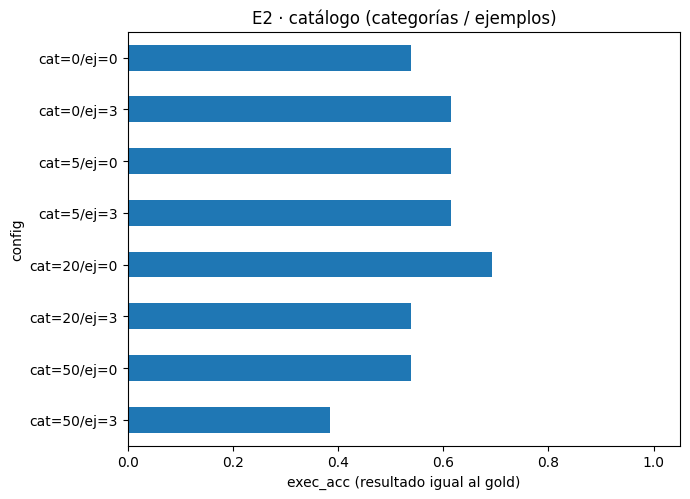

In [24]:
cfgs = [
    replace(MEJOR, nombre=f"cat={m}/ej={e}", max_categorias=m, n_ejemplos=e)
    for m in (0, 5, 20, 50) for e in (0, 3)
]

res2, MEJOR = correr_experimento("E2_catalogo", cfgs)
grafico(res2, "E2 · catálogo (categorías / ejemplos)")

## E3 · Prompt y formato de salida
- `fewshot`: agrega 4 ejemplos (con variables y preguntas distintas a las de evaluación).
- `schema`: salida estructurada con JSON Schema; el modelo **solo puede elegir variables que existen** (requiere `ollama` ≥ 0.4).

→ E3_prompt_formato: base+json
→ E3_prompt_formato: base+schema
→ E3_prompt_formato: fewshot+json
→ E3_prompt_formato: fewshot+schema


,exec_acc,exec_std,exact,plan_valido,op_ok,var_ok,filtros_ok,latencia_s,tokens_prompt,truncado,errores
config,,,,,,,,,,,
base+json,0.692,0.0,0.692,0.846,0.846,0.769,1.000,3.909,4575.077,0.0,0
base+schema,0.769,0.0,0.769,0.923,0.846,0.769,1.000,3.224,4575.077,0.0,0
fewshot+json,0.692,0.0,0.692,0.923,0.923,0.846,0.923,6.978,4769.083,0.0,1
fewshot+schema,0.769,0.0,0.769,1.000,1.000,0.923,1.000,3.225,4769.077,0.0,0


Mejor configuración del experimento: base+schema


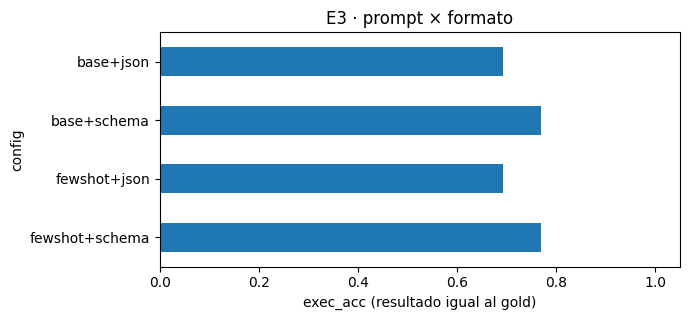

In [25]:
cfgs = [
    replace(MEJOR, nombre=f"{p}+{f}", prompt=p, formato=f)
    for p in ("base", "fewshot") for f in ("json", "schema")
]

res3, MEJOR = correr_experimento("E3_prompt_formato", cfgs)
grafico(res3, "E3 · prompt × formato")

## E4 · Temperatura
Con `temperature>0` se repite cada configuración `N_REP` veces con semillas distintas; `exec_std` mide la inestabilidad.
Para una tarea de extracción de JSON se espera que 0 sea lo mejor, pero conviene comprobarlo.

→ E4_temperatura: T=0.0
→ E4_temperatura: T=0.3
→ E4_temperatura: T=0.7
→ E4_temperatura: T=1.0


,exec_acc,exec_std,exact,plan_valido,op_ok,var_ok,filtros_ok,latencia_s,tokens_prompt,truncado,errores
config,,,,,,,,,,,
T=0.0,0.769,0.000,0.769,0.923,0.846,0.769,1.0,3.887,4575.077,0.0,0
T=0.3,0.744,0.044,0.744,0.923,0.846,0.769,1.0,3.233,4575.077,0.0,0
T=0.7,0.744,0.044,0.744,0.923,0.846,0.769,1.0,3.155,4575.077,0.0,0
T=1.0,0.744,0.044,0.744,0.923,0.846,0.769,1.0,3.185,4575.077,0.0,0


Mejor configuración del experimento: T=0.0


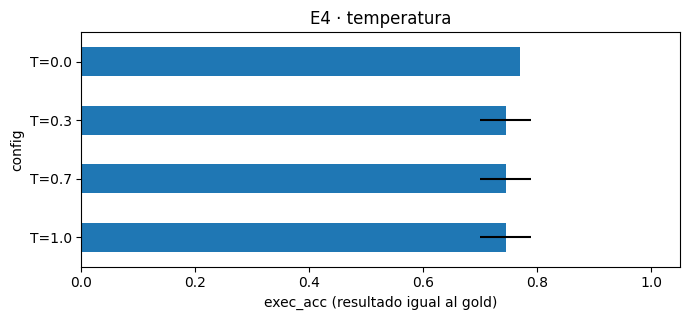

In [26]:
cfgs = [
    replace(MEJOR, nombre=f"T={t}", temperature=t)
    for t in (0.0, 0.3, 0.7, 1.0)
]

res4, MEJOR = correr_experimento("E4_temperatura", cfgs, N_REP)
grafico(res4, "E4 · temperatura")

## E5 · Penalización de repetición y muestreo
- `repeat_penalty` puede perjudicar a un JSON, que repite nombres de variables y claves por naturaleza.
- `top_p` / `top_k` solo tienen efecto con `temperature>0`; se evalúan a T=0.3 contra la configuración actual como referencia.

→ E5a_repeat_penalty: rp=default
→ E5a_repeat_penalty: rp=1.0
→ E5a_repeat_penalty: rp=1.3


,exec_acc,exec_std,exact,plan_valido,op_ok,var_ok,filtros_ok,latencia_s,tokens_prompt,truncado,errores
config,,,,,,,,,,,
rp=default,0.769,0.0,0.769,0.923,0.846,0.769,1.000,3.287,4575.077,0.0,0
rp=1.0,0.769,0.0,0.769,0.923,0.846,0.769,1.000,3.188,4575.077,0.0,0
rp=1.3,0.615,0.0,0.615,0.846,0.769,0.769,0.769,3.253,4575.167,0.0,1


Mejor configuración del experimento: rp=1.0
→ E5b_top_p_top_k: referencia
→ E5b_top_p_top_k: T0.3 p=0.5/k=10
→ E5b_top_p_top_k: T0.3 p=0.9/k=40
→ E5b_top_p_top_k: T0.3 p=1.0/k=100


,exec_acc,exec_std,exact,plan_valido,op_ok,var_ok,filtros_ok,latencia_s,tokens_prompt,truncado,errores
config,,,,,,,,,,,
referencia,0.769,0.000,0.769,0.923,0.846,0.769,1.0,3.239,4575.077,0.0,0
T0.3 p=0.5/k=10,0.769,0.000,0.769,0.923,0.846,0.769,1.0,3.256,4575.077,0.0,0
T0.3 p=0.9/k=40,0.744,0.044,0.744,0.923,0.846,0.769,1.0,3.254,4575.077,0.0,0
T0.3 p=1.0/k=100,0.744,0.044,0.744,0.923,0.846,0.769,1.0,3.244,4575.077,0.0,0


Mejor configuración del experimento: referencia


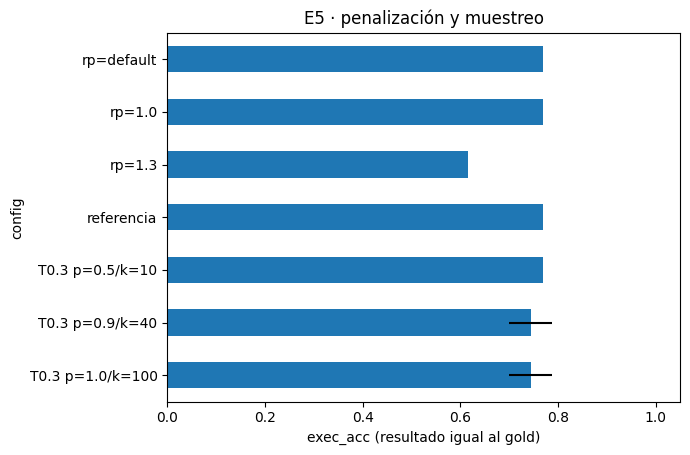

In [27]:
# E5a: repeat_penalty
cfgs = [
    replace(MEJOR, nombre=f"rp={r or 'default'}", repeat_penalty=r)
    for r in (None, 1.0, 1.3)
]
res5a, MEJOR = correr_experimento("E5a_repeat_penalty", cfgs, N_REP)

# E5b: top_p / top_k a T=0.3
cfgs = [replace(MEJOR, nombre="referencia")] + [
    replace(MEJOR, nombre=f"T0.3 p={p}/k={k}",
            temperature=0.3, top_p=p, top_k=k)
    for p, k in ((0.5, 10), (0.9, 40), (1.0, 100))
]
res5b, MEJOR = correr_experimento("E5b_top_p_top_k", cfgs, N_REP)
grafico(pd.concat([res5a, res5b]), "E5 · penalización y muestreo")